### FALTA:
[ ] observar gráficos após "divisão por gênero" e ver se está tudo correto

### **O que fazer até segunda: (30/10) **

## Checklist — Próximas Etapas (Checkpoint 2)

- [ ] **1. Análise de Padrão de Erros por Época**
  - [ ] Investigar se alguma década específica apresenta maior volume de dados faltantes ou inconsistências.
  - [ ] Documentar o contexto histórico/técnico dessas falhas temporais.

- [ ] **2. Recortes Temporais do Lucro (Ano e Década)**
  - [ ] Agrupar os dados financeiros por ano de lançamento e por décadas.
  - [ ] Mapear a evolução do lucro médio e total ao longo dos anos.

- [ ] **3. Gráfico Temporal de Gêneros por Década**
  - [ ] Cruzar a distribuição dos gêneros cinematográficos com as respectivas décadas.
  - [ ] Gerar visualização em barras (evitando gráficos de pizza) para demonstrar quais gêneros ganharam força (ex: ascensão de filmes de aventura/super-heróis).

- [ ] **4. Feature Engineering (*Engenharia de Atributos*)**
  - [ ] Criar novas colunas auxiliares relevantes para a análise (ex: coluna `decade`, faixas de orçamento ou métricas de retorno).

- [ ] **5. Extração de Insights e Correlações**
  - [ ] Relacionar a coluna `popularity` com o lucro e a receita ao longo do tempo.
  - [ ] Levantar fatos e dados interessantes sobre os filmes mais famosos de cada período histórico para o relatório final.

## Importação e Início

In [207]:
# utilizar os Dataframes do Pandas para manipular as instâncias
import pandas as pd
import numpy as np
# matplotlib e seaborn para visualizar
import matplotlib.pyplot as plt
import seaborn as sns
# gdown para baixar os dados
import gdown
plt.style.use('ggplot') 

In [208]:
url = 'https://drive.google.com/file/d/10izoanxrZJnQzkV9UpPI-DX9bt2mYG62/view'
output = 'filmes.json'
gdown.download(url=url, output=output, quiet=False)

Downloading...
From: https://drive.google.com/uc?id=10izoanxrZJnQzkV9UpPI-DX9bt2mYG62
To: /home/adrielly/Downloads/datascienceproject/filmes.json
100%|██████████| 31.8M/31.8M [00:07<00:00, 4.26MB/s]


'filmes.json'

In [209]:
df = pd.read_json('filmes.json', orient='records')

### Registrar o tamanho inicial do DataFrame

In [210]:
tamanho_inicial = len(df)
print(f"Número inicial de registros: {tamanho_inicial}")

relatorio_perdas = {"Etapa": ["Inicial"], "Registros Restantes": [tamanho_inicial], "Dados Perdidos": [0]}

def registrar_etapa(nome_etapa, df_atual):
    restantes = len(df_atual)
    perdidos = tamanho_inicial - restantes if nome_etapa == "Após Limpeza Completa" else relatorio_perdas["Registros Restantes"][-1] - restantes
    print(f"[{nome_etapa}] Restantes: {restantes} | Perdidos nesta etapa: {perdidos}")

Número inicial de registros: 16541


### 1. Remover colunas que não serão utilizadas

In [211]:
df.drop(columns=['backdrop_path', 'homepage', 'poster_path', 'status', 'adult', 'tagline'], inplace=True)
# Mantém 'popularity'

/tmp/ipykernel_21770/1481857215.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['backdrop_path', 'homepage', 'poster_path', 'status', 'adult', 'tagline'], inplace=True)


### 2. Verificação e Remoção de Duplicatas

In [212]:
tamanho_antes_dup = len(df)

colunas_comparaveis = [
    col for col in df.columns 
    if not isinstance(df[col].dropna().iloc[0], (list, dict))
]

duplicadas = df.duplicated(subset=colunas_comparaveis).sum()
df.drop_duplicates(subset=colunas_comparaveis, inplace=True)

perdidos_dup = tamanho_antes_dup - len(df)

print(f"Linhas duplicadas removidas: {perdidos_dup}")

/tmp/ipykernel_21770/1790571319.py:9: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(subset=colunas_comparaveis, inplace=True)


Linhas duplicadas removidas: 0


### 3. Verificações de Sanidade (Valores Impossíveis e Consistência)

In [213]:
tamanho_antes_sanidade = len(df)

condicao_sanidade = (
    (df['budget'] > 0) & 
    (df['revenue'] > 0) & 
    (df['vote_count'] > 0)
)

df = df[condicao_sanidade].copy()
perdidos_sanidade = tamanho_antes_sanidade - len(df)

print(f"Registros removidos por violação de sanidade (valores zerados/impossíveis): {perdidos_sanidade}")

Registros removidos por violação de sanidade (valores zerados/impossíveis): 2362


### 4. Remoção Estatística de Outliers (Método IQR)

In [214]:
tamanho_antes_iqr = len(df)

# protege temporariamente filmes com receita > 1 bilhão
blockbusters = df[df['revenue'] > 1_000_000_000].copy()
df_normal = df[df['revenue'] <= 1_000_000_000].copy()

def remover_outliers_iqr(data, coluna, fator=3.0):
    if coluna not in data.columns:
        return data
    Q1 = data[coluna].quantile(0.25)
    Q3 = data[coluna].quantile(0.75)
    IQR = Q3 - Q1
    limite_inferior = Q1 - fator * IQR
    limite_superior = Q3 + fator * IQR
    return data[(data[coluna] >= limite_inferior) & (data[coluna] <= limite_superior)]

df_normal = remover_outliers_iqr(df_normal, 'budget', fator=3.0)
df_normal = remover_outliers_iqr(df_normal, 'revenue', fator=3.0)

colunas_comparaveis = [
    col for col in df.columns 
    if not isinstance(df[col].dropna().iloc[0] if len(df[col].dropna()) > 0 else '', (list, dict))
]

df = pd.concat([df_normal, blockbusters]).drop_duplicates(subset=colunas_comparaveis).reset_index(drop=True)

perdidos_iqr = tamanho_antes_iqr - len(df)
print(f"Registros removidos por Outliers Estatísticos (com blockbusters preservados): {perdidos_iqr}")

Registros removidos por Outliers Estatísticos (com blockbusters preservados): 1637


In [215]:
tamanho_final = len(df)
total_perdidos = tamanho_inicial - tamanho_final
percentual_perdido = (total_perdidos / tamanho_inicial) * 100

relatorio_impacto = pd.DataFrame({
    'Etapa do Processo': [
        'Tamanho Inicial', 
        'Remoção de Duplicatas', 
        'Verificação de Sanidade (Sem Zeros)', 
        'Outliers Estatísticos (IQR)', 
        'Tamanho Final'
    ],
    'Registros Restantes': [
        tamanho_inicial, 
        tamanho_inicial - perdidos_dup, 
        tamanho_inicial - perdidos_dup - perdidos_sanidade, 
        tamanho_final, 
        tamanho_final
    ],
    'Dados Perdidos na Etapa': [
        0, 
        perdidos_dup, 
        perdidos_sanidade, 
        perdidos_iqr, 
        total_perdidos
    ]
})

display(relatorio_impacto)
print(f"Percentual total de dados perdidos na limpeza: {percentual_perdido:.2f}%")

,Etapa do Processo,Registros Restantes,Dados Perdidos na Etapa
0,Tamanho Inicial,16541,0
1,Remoção de Duplicatas,16541,0
2,Verificação de Sanidade (Sem Zeros),14179,2362
3,Outliers Estatísticos (IQR),12542,1637
4,Tamanho Final,12542,3999


Percentual total de dados perdidos na limpeza: 24.18%


## Divisão por Filme

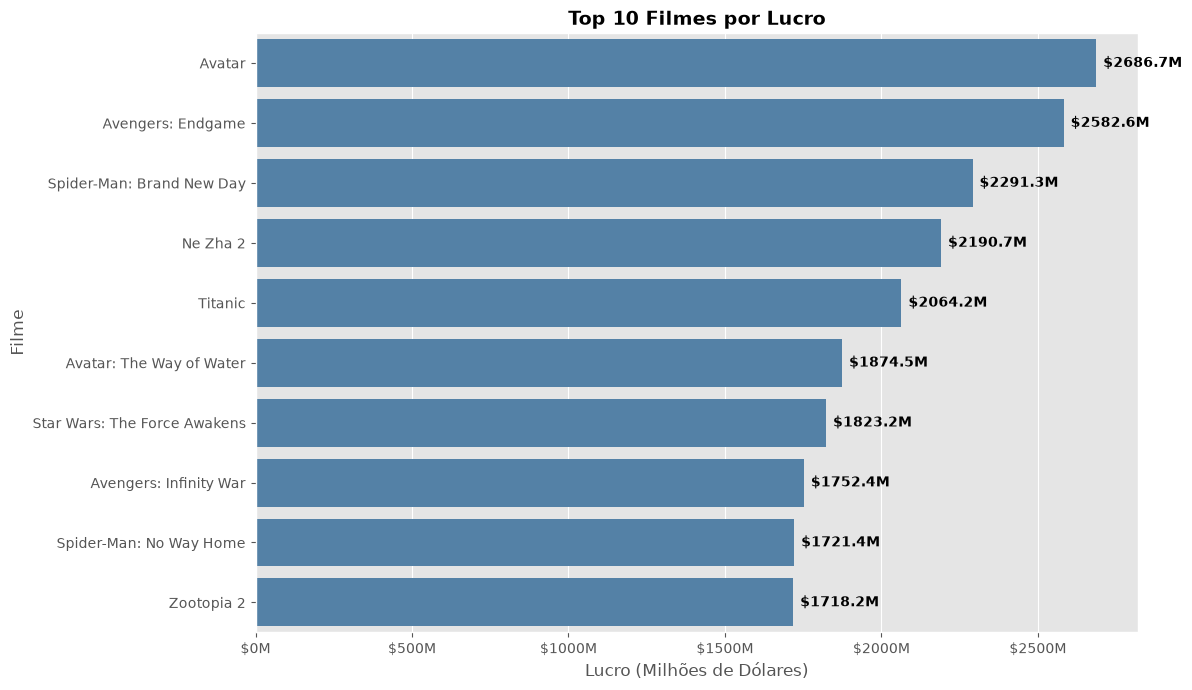

In [216]:
top_10_movies = df.nlargest(10, 'profit').sort_values('profit', ascending=False)

plt.figure(figsize=(12, 7))
ax = sns.barplot(
    data=top_10_movies,
    x='profit',
    y='title',
    color='steelblue'
)

ax.set_title('Top 10 Filmes por Lucro', fontsize=14, fontweight='bold')
ax.set_xlabel('Lucro (Milhões de Dólares)', fontsize=12)
ax.set_ylabel('Filme', fontsize=12)

ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f'${value / 1_000_000:.0f}M')
)

for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.annotate(
            f'${width / 1_000_000:.1f}M',
            xy=(width, p.get_y() + p.get_height() / 2),
            xytext=(5, 0),  # pequeno deslocamento horizontal
            textcoords='offset points',
            ha='left',
            va='center',
            fontsize=10,
            fontweight='bold'
        )

plt.tight_layout()
plt.show()

## Divisão Por Gênero

In [217]:
df_genres = df.explode('genres').copy()
df_genres['genre'] = df_genres['genres'].apply(
    lambda x: x.get('name') if isinstance(x, dict) else np.nan
)
df_genres.drop(columns='genres', inplace=True)

/tmp/ipykernel_21770/2445491170.py:5: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_genres.drop(columns='genres', inplace=True)


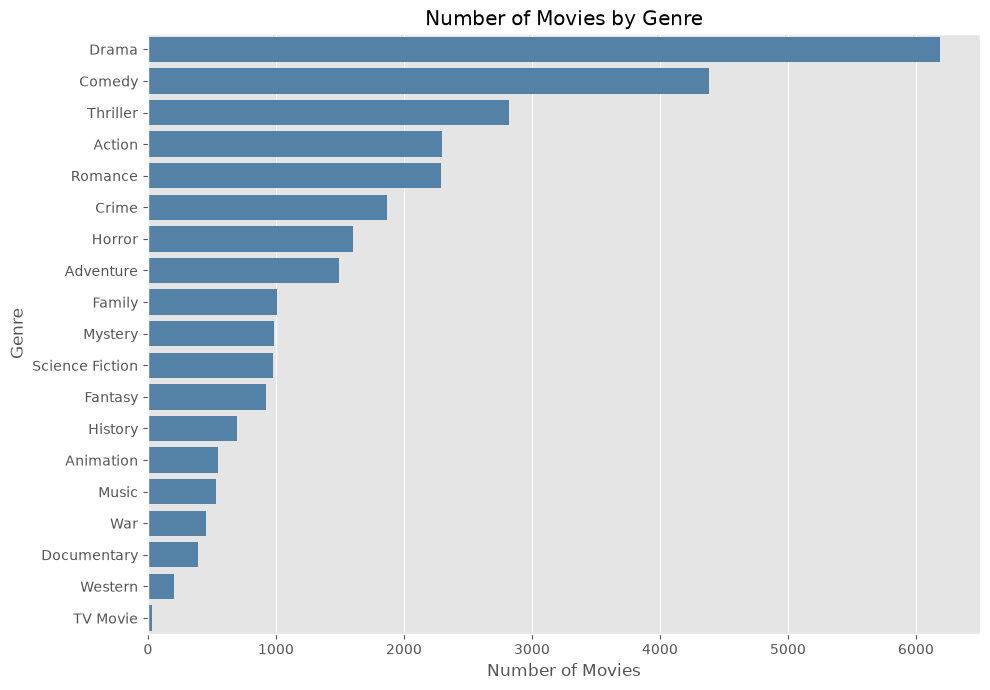

In [218]:
genre_counts = df_genres['genre'].dropna().value_counts()

plt.figure(figsize=(10, 7))

ax = sns.barplot(
    x=genre_counts.values,
    y=genre_counts.index,
    color='steelblue'
)

ax.set_title('Number of Movies by Genre')
ax.set_xlabel('Number of Movies')
ax.set_ylabel('Genre')

plt.tight_layout()
plt.show()

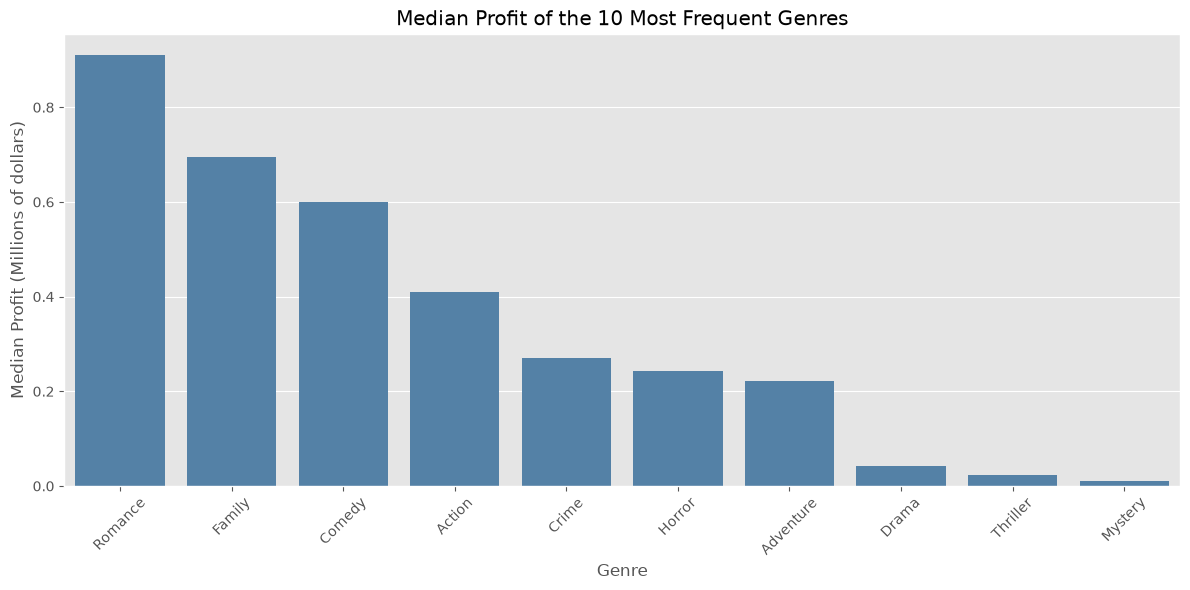

In [219]:
top_10_genres = df_genres['genre'].dropna().value_counts().head(10).index.tolist()

median_profit_by_genre = (
    df_genres[df_genres['genre'].isin(top_10_genres)]
    .groupby('genre')['profit']
    .median()
    .sort_values(ascending=False)
    / 1_000_000
)

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    x=median_profit_by_genre.index,
    y=median_profit_by_genre.values,
    color='steelblue'
)

ax.set_title('Median Profit of the 10 Most Frequent Genres')
ax.set_xlabel('Genre')
ax.set_ylabel('Median Profit (Millions of dollars)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


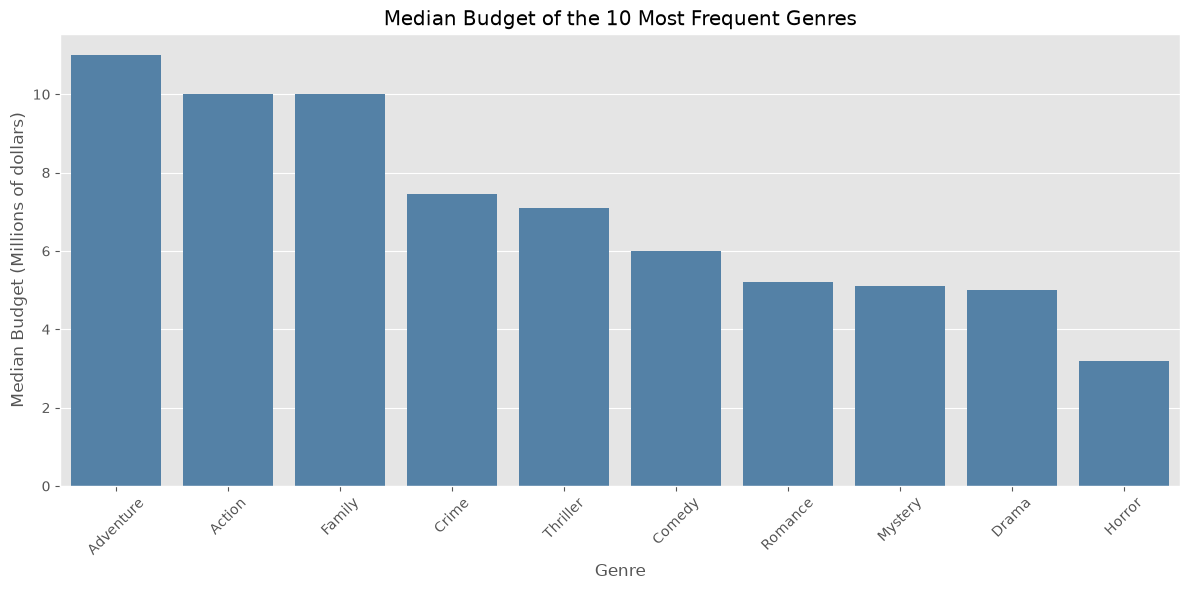

In [220]:
median_budget_by_genre = (
    df_genres[df_genres['genre'].isin(top_10_genres)]
    .groupby('genre')['budget']
    .median()
    .sort_values(ascending=False)
    / 1_000_000
)

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    x=median_budget_by_genre.index,
    y=median_budget_by_genre.values,
    color='steelblue'
)

ax.set_title('Median Budget of the 10 Most Frequent Genres')
ax.set_xlabel('Genre')
ax.set_ylabel('Median Budget (Millions of dollars)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## Divisão Por Coleções

In [221]:
df['collection'] = df['belongs_to_collection'].apply(
    lambda collection: collection.get('name')
    if isinstance(collection, dict)
    else np.nan
)

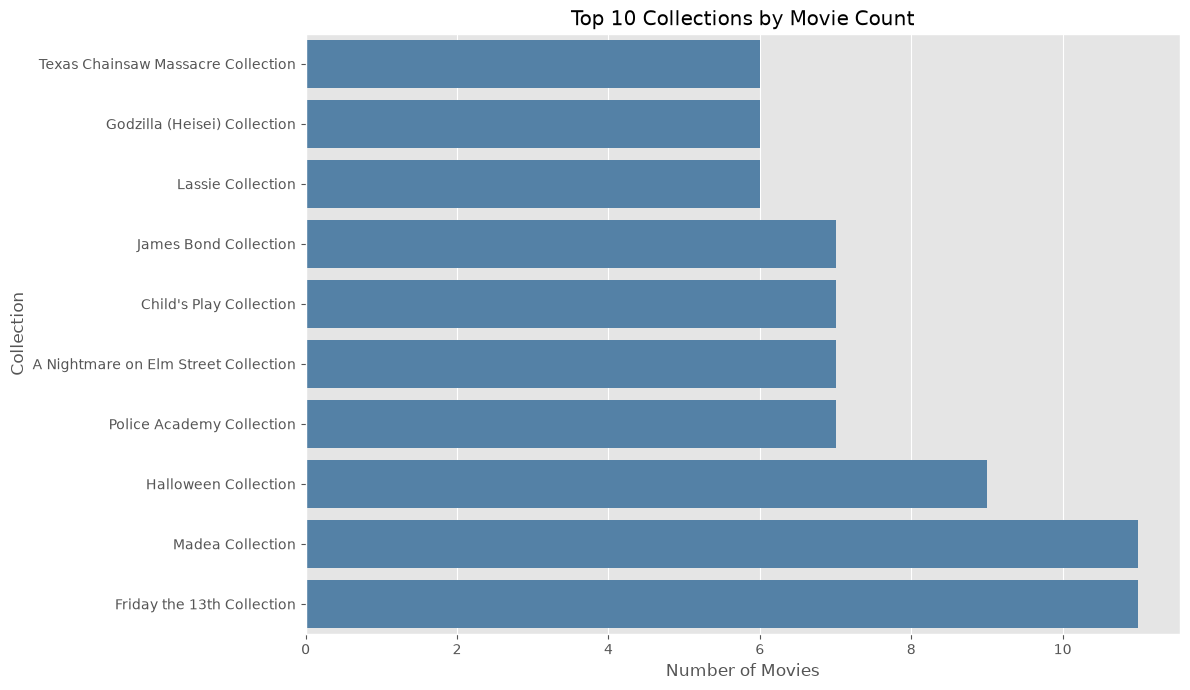

In [222]:
top_collections = (
    df['collection']
    .dropna()
    .value_counts()
    .head(10)
    .sort_values()
)

plt.figure(figsize=(12, 7))
ax = sns.barplot(
    x=top_collections.values,
    y=top_collections.index,
    color='steelblue'
)

ax.set_title('Top 10 Collections by Movie Count')
ax.set_xlabel('Number of Movies')
ax.set_ylabel('Collection')

plt.tight_layout()
plt.show()

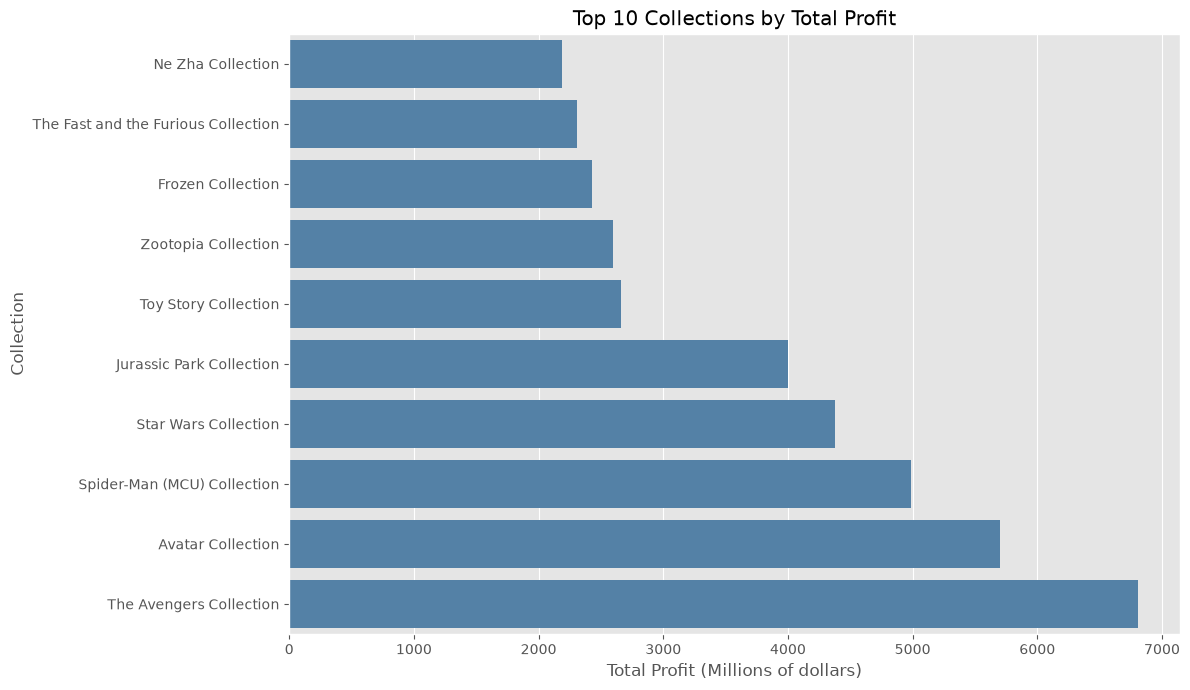

In [223]:
top_collections_by_profit = (
    df.dropna(subset=['collection'])
      .groupby('collection')['profit']
      .sum()
      .nlargest(10)
      .sort_values()
)

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    x=top_collections_by_profit.values / 1_000_000,
    y=top_collections_by_profit.index,
    color='steelblue'
)

ax.set_title('Top 10 Collections by Total Profit')
ax.set_xlabel('Total Profit (Millions of dollars)')
ax.set_ylabel('Collection')

plt.tight_layout()
plt.show()

## Analise de ROI

In [224]:
top_roi_movies = (
    df
    .nlargest(10, 'roi')
    .sort_values('roi')
)

top_roi_movies[['title', 'roi', 'budget', 'revenue', 'vote_count']]


,title,roi,budget,revenue,vote_count
8966,The Parmesan Thieves,2.666657e+05,3,800000,1
4943,Noticias de Medianoche,9.999990e+05,10,10000000,1
912,The Western,1.254544e+06,55,69000000,1
7222,The Judas Project,1.425066e+06,2,2850135,5
4447,The Beatles: Eight Days a Week - The Touring Y...,2.456759e+06,5,12283800,397
6221,East of Eden,2.499999e+06,2,5000000,846
7271,Between Us,2.755583e+06,1,2755584,19
5910,Oy Vey! My Son Is Gay!,3.000002e+06,2,6000007,33
4942,CONTRATADO,9.999999e+06,1,10000000,1
341,DOFE THE MOVIE,1.000000e+08,1,100000000,1
